# ResNet Autoencoder: Image Reconstruction with ImageNette

**Project:** Advanced Models of Deep Learning — Midterm  
**Base implementation:** [JiahongChen/ResNet-decoder](https://github.com/JiahongChen/ResNet-decoder)  
**Dataset:** [ImageNette](https://github.com/fastai/imagenette)

## Project objective
I choose this topic because it fit the critaeria of me wanting to setup my own home workstation to be able to handle training a small scale model instead of using the tesla server. I went on a journey of downloading all the dependencies and was able to use my own NVIDIA GPU to train the model which was a RTX 5070TI with 16GB's of GPU memory.

I had to do fresh install of the following dependencies on my system for it to be able to support my graphics card.
The following are the dependencies that i had to install before starting my journey.
Python 3.11: Python environment
Git: Version control system and to grab code from the provided github
PyTorch and TorchVision: Deep learning and image processing
CUDA-enabled PyTorch: In order to utilize my RTX 5070ti, I had to download a version that supported my GPU
JupyterLab: To run an interactive notebook environment on my local host
NumPy, Pandas, and Pillow: These were utilized for data handling and image processing
Matplotlib: Utilized to plot graphs in order to do comparisons.
scikit-learn: Metric evaluation
tqdm: Progress bar display while training the model

The next cell verifies that PyTorch can access the NVIDIA GPU and that the ImageNette training and validation folders exist.

In [1]:
import sys
import torch
import torchvision
from pathlib import Path

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

# Check ImageNette dataset
data_dir = Path("data/imagenette2-160")

print("Training dataset exists:", (data_dir / "train").is_dir())
print("Validation dataset exists:", (data_dir / "val").is_dir())

Python: 3.11.9
PyTorch: 2.12.1+cu130
TorchVision: 0.27.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Ti
GPU memory: 15.89 GB
Training dataset exists: True
Validation dataset exists: True


## 2. ImageNette

`ImageFolder` loads images from class-organized folders. The transform resizes each image to **221×221** and converts pixel values to floating-point tensors in **[0, 1]**. 

`DataLoader` groups samples into batches, randomizes training order, and leaves validation order fixed.

The labels are useful for identifying example categories, but **they are not used as targets** when training the autoencoder: its target is the original image itself.

The sample images and printed tensor shape verify that the preprocessing works before model training.

Training images: 9469
Validation images: 3925
Number of classes: 10
Batch shape: torch.Size([4, 3, 221, 221])
Pixel range: 0.0 1.0


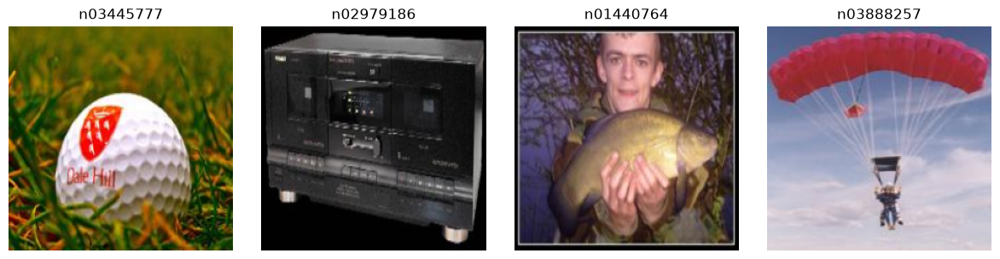

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Resize images to the repository's expected resolution
transform = transforms.Compose([
    transforms.Resize((221, 221)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    root=data_dir / "train",
    transform=transform
)

val_dataset = datasets.ImageFolder(
    root=data_dir / "val",
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Batch shape:", images.shape)
print("Pixel range:", images.min().item(), images.max().item())

# Display example training images
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(images[i].permute(1, 2, 0))
    ax.set_title(train_dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Build and check the encoder–decoder architecture

The model uses a ResNet-50-style encoder built from bottleneck residual blocks and a corresponding decoder from the referenced repository. Residual connections help information and gradients move through deep networks. The decoder uses transposed-convolution operations and encoder-provided pooling indices to expand features back into an RGB image.

The first forward pass checks whether input and reconstruction shapes match, before loading pretrained encoder weights or training the decoder. A correctly shaped output is necessary for pixel-wise MSE, but it does not mean the reconstruction is accurate.

The decoder receives pooling indices in addition to the latent tensor, so the latent representation is not the only information it uses.

In [3]:
import res_encoder as enc
import res_decoder as dec

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ResNet-50 encoder
encoder = enc.ResNet(
    enc.Bottleneck,
    [3, 4, 6, 3],
    return_indices=True
).to(device)

# Transposed ResNet-50 decoder
decoder = dec.ResNet(
    dec.Bottleneck,
    [3, 6, 4, 3]
).to(device)

encoder.eval()
decoder.eval()

# Test one image without training
test_image = images[:1].to(device)

with torch.inference_mode():
    features, indices = encoder(test_image)
    reconstruction = decoder(features, indices)

print("Input shape:", test_image.shape)
print("Encoded features:", features.shape)
print("Reconstruction shape:", reconstruction.shape)

print("Encoder parameters:",
      sum(p.numel() for p in encoder.parameters()))

print("Decoder parameters:",
      sum(p.numel() for p in decoder.parameters()))

assert reconstruction.shape == test_image.shape
print("Architecture shape test passed!")

Input shape: torch.Size([1, 3, 221, 221])
Encoded features: torch.Size([1, 2048, 1, 1])
Reconstruction shape: torch.Size([1, 3, 221, 221])
Encoder parameters: 25557032
Decoder parameters: 21825734
Architecture shape test passed!


## 4. Initialize pretrained features and freeze the encoder

The next cell copies TorchVision's pretrained ResNet-50 weights into the custom encoder and freezes its parameters using requires_grad=False.

Images are normalized with the ImageNet RGB means and standard deviations before passing through the pretrained encoder. The reconstruction target remains the original [0, 1] image. The decoder's final activation is changed to Sigmoid so its output values are also bounded to [0, 1].

I did not know until i had to look it up but freezing the encoder reduces training work.Its features are learned for classification rather than reconstruction.

In [4]:
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Load pretrained ResNet-50
weights = ResNet50_Weights.DEFAULT
pretrained = resnet50(weights=weights)

# Transfer weights into our custom encoder
encoder.load_state_dict(pretrained.state_dict(), strict=True)
del pretrained

# Freeze encoder parameters
for parameter in encoder.parameters():
    parameter.requires_grad = False

encoder.eval()

# Bound reconstruction values to [0, 1]
decoder.relu = nn.Sigmoid()
decoder.train()

# ImageNet normalization for pretrained encoder
mean = torch.tensor(
    [0.485, 0.456, 0.406], device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=device
).view(1, 3, 1, 1)

def reconstruct(x):
    normalized = (x - mean) / std

    with torch.no_grad():
        features, indices = encoder(normalized)

    return decoder(features, indices)

print("Pretrained encoder loaded")
print("Encoder frozen:",
      not any(p.requires_grad for p in encoder.parameters()))
print("Decoder ready for training")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Semih/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 108MB/s] 


Pretrained encoder loaded
Encoder frozen: True
Decoder ready for training


## 5. Reconstruction loss, optimizer, and gradient check

The objective here in the next cell is to minimize the mean squared error between each predicted pixel and its corresponding input pixel.

Only decoder parameters are passed to the Adam optimizer. The next cell runs one forward pass, computes mean squared error, performs backpropagation, and takes one optimizer step. This is a quick check that the network can actually train and that its output and target shapes agree. This cell itself updates the decoder once before the first multi-epoch training experiment.

In [5]:
# Reconstruction loss
criterion = nn.MSELoss()

# Train decoder parameters only
optimizer = torch.optim.Adam(
    decoder.parameters(),
    lr=0.0003
)

# Test one forward and backward pass
decoder.train()
x = images.to(device)

optimizer.zero_grad(set_to_none=True)

output = reconstruct(x)
loss = criterion(output, x)

loss.backward()
optimizer.step()

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Initial MSE:", round(loss.item(), 6))
print("Backward pass successful")

Input shape: torch.Size([4, 3, 221, 221])
Output shape: torch.Size([4, 3, 221, 221])
Initial MSE: 0.134876
Backward pass successful


## 6. Experiment 1 — Train the original 1×1 model on a small subset

To establish a fast initial baseline, the notebook samples 512 training images and 128 validation images. The encoder stays frozen; the decoder trains for three epochs using Adam and MSE.

After each epoch, the model is evaluated in eval() mode on the validation subset. The checkpoint with the lowest validation MSE is saved. Keeping validation separate from the optimizer's training batches helps assess whether reconstruction improves beyond the training images.

In [6]:
from torch.utils.data import Subset
from tqdm.auto import tqdm

torch.manual_seed(42)

# Reproducible subsets
train_indices = torch.randperm(
    len(train_dataset)
)[:512].tolist()

val_indices = torch.randperm(
    len(val_dataset)
)[:128].tolist()

small_train_loader = DataLoader(
    Subset(train_dataset, train_indices),
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

small_val_loader = DataLoader(
    Subset(val_dataset, val_indices),
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

epochs = 3
train_losses = []
val_losses = []
best_val_loss = float("inf")

for epoch in range(epochs):
    decoder.train()
    encoder.eval()

    running_loss = 0.0

    for x, _ in tqdm(small_train_loader,
                      desc=f"Epoch {epoch+1}/{epochs}"):

        x = x.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        output = reconstruct(x)
        loss = criterion(output, x)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)

    train_loss = running_loss / len(small_train_loader.dataset)
    train_losses.append(train_loss)

    decoder.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for x, _ in small_val_loader:
            x = x.to(device, non_blocking=True)
            output = reconstruct(x)
            loss = criterion(output, x)
            running_val_loss += loss.item() * x.size(0)

    val_loss = running_val_loss / len(small_val_loader.dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}: "
        f"Train MSE={train_loss:.6f}, "
        f"Val MSE={val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(decoder.state_dict(), "best_decoder.pth")

print("Training experiment complete")
print("Best validation MSE:", best_val_loss)

C:\Users\Semih\DeepLearningMidterm\ResNet-decoder\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Epoch 1/3: 100%|██████████| 128/128 [00:07<00:00, 17.88it/s]


Epoch 1: Train MSE=0.084980, Val MSE=0.081118


Epoch 2/3: 100%|██████████| 128/128 [00:04<00:00, 26.67it/s]


Epoch 2: Train MSE=0.078968, Val MSE=0.089095


Epoch 3/3: 100%|██████████| 128/128 [00:04<00:00, 26.52it/s]


Epoch 3: Train MSE=0.073334, Val MSE=0.073238
Training experiment complete
Best validation MSE: 0.07323791238013655


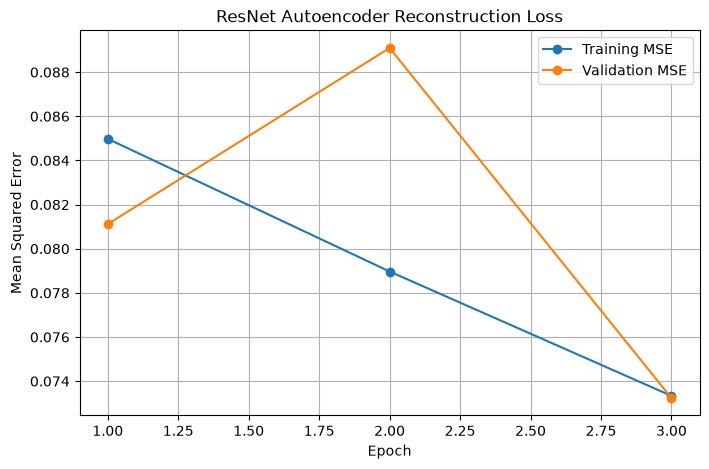

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o",
    label="Training MSE"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    marker="o",
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("ResNet Autoencoder Reconstruction Loss")
plt.legend()
plt.grid(True)
plt.show()

## 7. Inspect the original model

This section restores the lowest-validation-loss checkpoint and plots original images above their reconstructions. Visual inspection matters because lower pixel-wise MSE does not guarantee visually recognizable output.

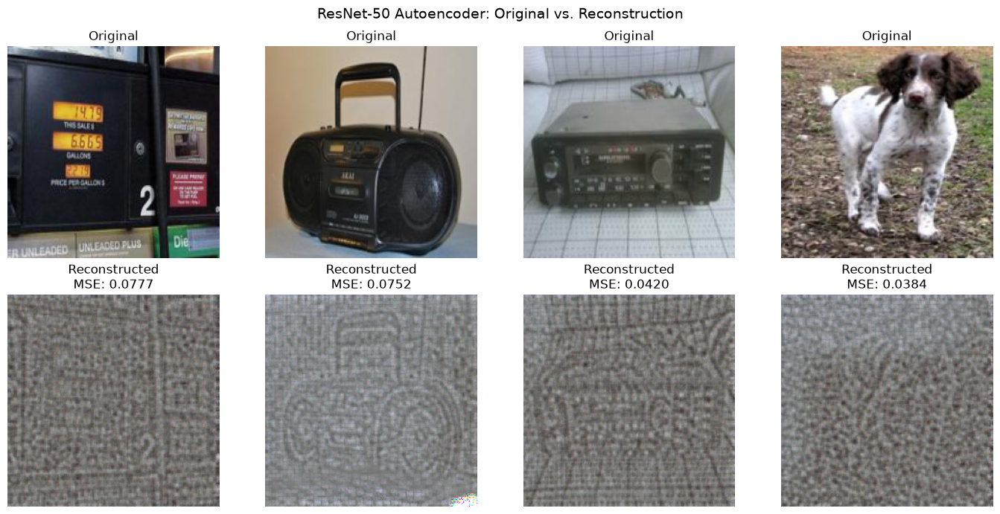

In [8]:
# Load the best-performing decoder
decoder.load_state_dict(
    torch.load(
        "best_decoder.pth",
        map_location=device,
        weights_only=True
    )
)

encoder.eval()
decoder.eval()

# Select four validation images
val_images, _ = next(iter(small_val_loader))
val_images = val_images[:4].to(device)

# Reconstruct images
with torch.inference_mode():
    reconstructed = reconstruct(val_images)

# Move images to CPU for visualization
original = val_images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    axes[0, i].imshow(
        original[i].permute(1, 2, 0)
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed[i].permute(1, 2, 0).clamp(0, 1)
    )

    mse = torch.mean(
        (original[i] - reconstructed[i]) ** 2
    ).item()

    axes[1, i].set_title(
        f"Reconstructed\nMSE: {mse:.4f}"
    )
    axes[1, i].axis("off")

plt.suptitle(
    "ResNet-50 Autoencoder: Original vs. Reconstruction",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "reconstruction_examples.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 8. Diagnostic — Compare against a constant-gray baseline

The next cell checks whether the reconstructions are genuinely informative or merely close to an average gray image. It compares MSE on four example images against a constant-gray prediction and measures per-channel pixel means and standard deviations.

This is a four-image diagnostic, not the final held-out evaluation. Low reconstruction standard deviation can help explain muted colors and contrast.

In [9]:
# Compare reconstruction statistics with the originals

encoder.eval()
decoder.eval()

x = val_images.to(device)

with torch.inference_mode():
    pred = reconstruct(x)

    # Simple constant-gray baseline
    gray_baseline = torch.full_like(x, 0.5)

    model_mse = criterion(pred, x).item()
    baseline_mse = criterion(gray_baseline, x).item()

print("Model MSE:", round(model_mse, 6))
print("Gray baseline MSE:", round(baseline_mse, 6))

print("\nOriginal image statistics:")
print("Mean:", x.mean(dim=(0, 2, 3)).cpu().numpy())
print("Std:", x.std(dim=(0, 2, 3)).cpu().numpy())

print("\nReconstructed image statistics:")
print("Mean:", pred.mean(dim=(0, 2, 3)).cpu().numpy())
print("Std:", pred.std(dim=(0, 2, 3)).cpu().numpy())

print("\nFinal decoder layers:")
print("Output normalization:", decoder.bn1)
print("Output activation:", decoder.relu)

Model MSE: 0.05833
Gray baseline MSE: 0.066325

Original image statistics:
Mean: [0.4246282  0.4123987  0.39658573]
Std: [0.24712653 0.23945922 0.23772849]

Reconstructed image statistics:
Mean: [0.47561148 0.47305214 0.4680532 ]
Std: [0.07171924 0.07624552 0.08392147]

Final decoder layers:
Output normalization: BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
Output activation: Sigmoid()


## 9. Experiment 2 — Remove the decoder's final BatchNorm

A copy of the trained decoder is created, and only its final output BatchNorm is replaced by nn.Identity(). Internal normalization layers remain unchanged. Comparing performance immediately after this replacement and after additional training helps distinguish an immediate architectural effect from subsequent optimization.

Because the new decoder starts from trained weights, this is an exploratory modification, not an experiment with fresh identical initializations.

In [10]:
import copy

# Preserve the original trained decoder
decoder.eval()

# Create a copy for Experiment 2
decoder_v2 = copy.deepcopy(decoder).to(device)

# Remove ONLY final output BatchNorm
decoder_v2.bn1 = nn.Identity()

# Keep output values between 0 and 1
decoder_v2.relu = nn.Sigmoid()

def reconstruct_with(x, model):
    normalized = (x - mean) / std

    with torch.no_grad():
        features, indices = encoder(normalized)

    return model(features, indices)

def evaluate_decoder(model):
    model.eval()
    total_loss = 0.0

    with torch.inference_mode():
        for x, _ in small_val_loader:
            x = x.to(device)
            pred = reconstruct_with(x, model)

            total_loss += (
                criterion(pred, x).item() * x.size(0)
            )

    return total_loss / len(small_val_loader.dataset)

# Compare both using the same 128 validation images
baseline_mse = evaluate_decoder(decoder)
modified_initial_mse = evaluate_decoder(decoder_v2)

print(f"Original model MSE: {baseline_mse:.6f}")
print(f"Modified model before fine-tuning: {modified_initial_mse:.6f}")
print("Final normalization:", decoder_v2.bn1)

Original model MSE: 0.073226
Modified model before fine-tuning: 0.076782
Final normalization: Identity()


In [11]:
optimizer_v2 = torch.optim.Adam(
    decoder_v2.parameters(),
    lr=0.0001
)

epochs_v2 = 2
v2_train_losses = []
v2_val_losses = []

best_v2_loss = float("inf")

for epoch in range(epochs_v2):
    encoder.eval()
    decoder_v2.train()
    running_loss = 0.0

    for x, _ in tqdm(
        small_train_loader,
        desc=f"Modified model epoch {epoch+1}/{epochs_v2}"
    ):
        x = x.to(device)

        optimizer_v2.zero_grad(set_to_none=True)

        pred = reconstruct_with(x, decoder_v2)
        loss = criterion(pred, x)

        loss.backward()
        optimizer_v2.step()

        running_loss += loss.item() * x.size(0)

    train_mse = running_loss / len(small_train_loader.dataset)
    val_mse = evaluate_decoder(decoder_v2)

    v2_train_losses.append(train_mse)
    v2_val_losses.append(val_mse)

    print(
        f"Epoch {epoch+1}: "
        f"Train MSE={train_mse:.6f}, "
        f"Validation MSE={val_mse:.6f}"
    )

    if val_mse < best_v2_loss:
        best_v2_loss = val_mse
        torch.save(
            decoder_v2.state_dict(),
            "best_decoder_no_output_bn.pth"
        )

print("\nOriginal validation MSE:", round(baseline_mse, 6))
print("Best modified validation MSE:", round(best_v2_loss, 6))

Modified model epoch 1/2: 100%|██████████| 128/128 [00:04<00:00, 26.31it/s]


Epoch 1: Train MSE=0.068996, Validation MSE=0.066903


Modified model epoch 2/2: 100%|██████████| 128/128 [00:04<00:00, 26.90it/s]


Epoch 2: Train MSE=0.066512, Validation MSE=0.067629

Original validation MSE: 0.073226
Best modified validation MSE: 0.066903


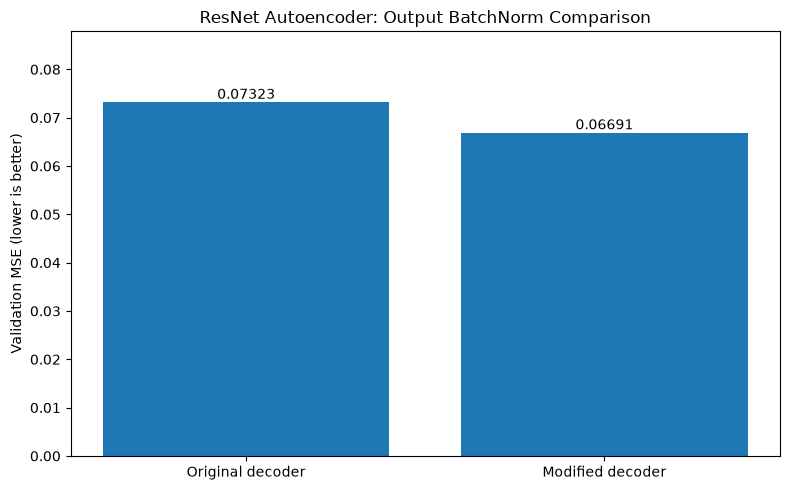

Original: 0.073226
Modified: 0.066912


In [12]:
decoder_v2.load_state_dict(
    torch.load(
        "best_decoder_no_output_bn.pth",
        map_location=device,
        weights_only=True
    )
)

final_modified_mse = evaluate_decoder(decoder_v2)

labels = ["Original decoder", "Modified decoder"]
scores = [baseline_mse, final_modified_mse]

plt.figure(figsize=(8, 5))
plt.bar(labels, scores)

plt.ylabel("Validation MSE (lower is better)")
plt.title("ResNet Autoencoder: Output BatchNorm Comparison")
plt.ylim(0, max(scores) * 1.2)

for i, score in enumerate(scores):
    plt.text(i, score, f"{score:.5f}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("decoder_comparison.png", dpi=150)
plt.show()

print("Original:", round(baseline_mse, 6))
print("Modified:", round(final_modified_mse, 6))

## 10. Comparison control — Extend training of the original decoder

The BatchNorm-modified decoder received two additional epochs. Here the original decoder is also trained for two further epochs using the same nominal learning rate to make the comparison less uneven.

The two runs still differ in mini-batch order and optimizer state, so their small difference should not be interpreted as a clean causal estimate of BatchNorm's effect.

In [13]:
# Experiment 3: Continue training original decoder
# for an equal total training budget.

optimizer_original = torch.optim.Adam(
    decoder.parameters(),
    lr=0.0001
)

best_original_mse = evaluate_decoder(decoder)

torch.save(
    decoder.state_dict(),
    "best_original_5epoch_control.pth"
)

original_extra_train = []
original_extra_val = []

for epoch in range(2):
    encoder.eval()
    decoder.train()

    running_loss = 0.0

    for x, _ in tqdm(
        small_train_loader,
        desc=f"Original control epoch {epoch+1}/2"
    ):
        x = x.to(device)

        optimizer_original.zero_grad(set_to_none=True)

        pred = reconstruct_with(x, decoder)
        loss = criterion(pred, x)

        loss.backward()
        optimizer_original.step()

        running_loss += loss.item() * x.size(0)

    train_mse = (
        running_loss / len(small_train_loader.dataset)
    )

    val_mse = evaluate_decoder(decoder)

    original_extra_train.append(train_mse)
    original_extra_val.append(val_mse)

    print(
        f"Epoch {epoch+1}: "
        f"Train MSE={train_mse:.6f}, "
        f"Validation MSE={val_mse:.6f}"
    )

    if val_mse < best_original_mse:
        best_original_mse = val_mse

        torch.save(
            decoder.state_dict(),
            "best_original_5epoch_control.pth"
        )

# Load best original checkpoint
decoder.load_state_dict(
    torch.load(
        "best_original_5epoch_control.pth",
        map_location=device,
        weights_only=True
    )
)

print("\nCONTROLLED COMPARISON")
print("Original decoder:", round(best_original_mse, 6))
print("Modified decoder:", round(final_modified_mse, 6))

Original control epoch 1/2: 100%|██████████| 128/128 [00:04<00:00, 26.58it/s]


Epoch 1: Train MSE=0.069450, Validation MSE=0.068941


Original control epoch 2/2: 100%|██████████| 128/128 [00:04<00:00, 26.64it/s]


Epoch 2: Train MSE=0.066586, Validation MSE=0.067150

CONTROLLED COMPARISON
Original decoder: 0.06715
Modified decoder: 0.066912


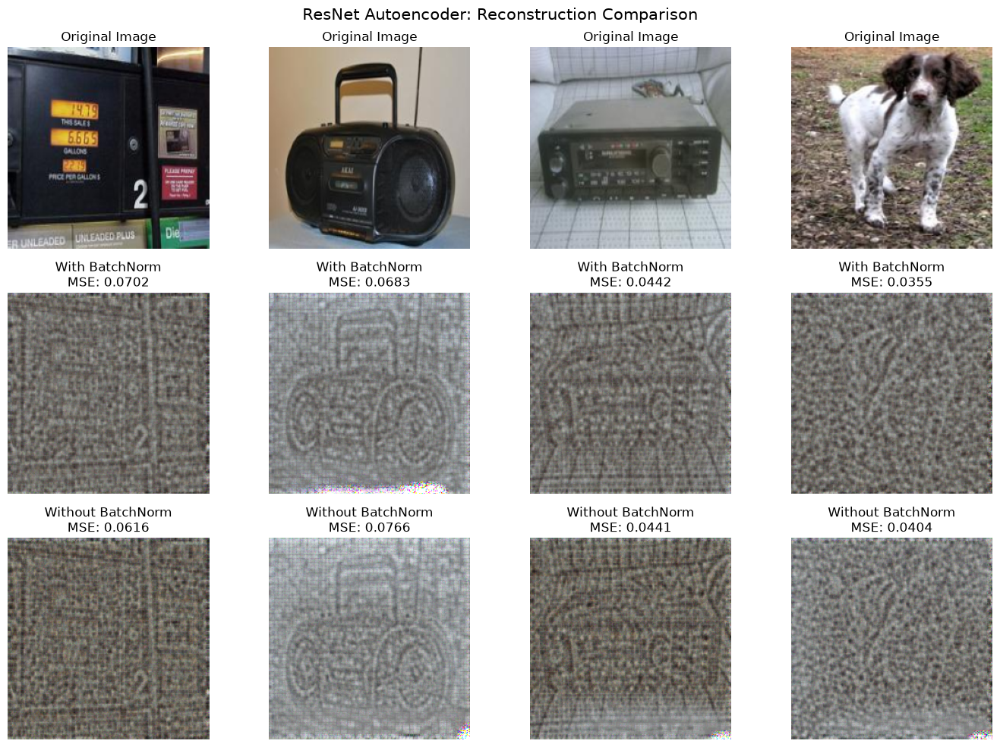

In [14]:
encoder.eval()
decoder.eval()
decoder_v2.eval()

x = val_images.to(device)

with torch.inference_mode():
    original_output = reconstruct_with(x, decoder)
    modified_output = reconstruct_with(x, decoder_v2)

original_output = original_output.cpu()
modified_output = modified_output.cpu()
inputs = x.cpu()

fig, axes = plt.subplots(
    3, 4,
    figsize=(14, 10)
)

for i in range(4):
    axes[0, i].imshow(inputs[i].permute(1, 2, 0))
    axes[0, i].set_title("Original Image")

    axes[1, i].imshow(
        original_output[i].permute(1, 2, 0).clamp(0, 1)
    )

    mse_original = torch.mean(
        (inputs[i] - original_output[i]) ** 2
    ).item()

    axes[1, i].set_title(
        f"With BatchNorm\nMSE: {mse_original:.4f}"
    )

    axes[2, i].imshow(
        modified_output[i].permute(1, 2, 0).clamp(0, 1)
    )

    mse_modified = torch.mean(
        (inputs[i] - modified_output[i]) ** 2
    ).item()

    axes[2, i].set_title(
        f"Without BatchNorm\nMSE: {mse_modified:.4f}"
    )

    for row in range(3):
        axes[row, i].axis("off")

plt.suptitle(
    "ResNet Autoencoder: Reconstruction Comparison",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    "final_reconstruction_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 11. Experiment 3 — Preserve the 7×7 spatial feature map

The original encoder ends with global average pooling, reducing its final feature map from 2048×7×7 to 2048×1×1. In this experiment, avgpool is replaced with nn.Identity(), retaining the 7×7 map.

This changes the latent size from 2,048 to 100,352 values per image. The decoder uses a previously trained checkpoint, then undergoes additional optimization for the changed input. We first verify that the modified model still reconstructs an image of the same shape.

I think that keeping spatial positions may help reconstruct locations and shapes, but it also retains more information. The comparison is not equal-capacity or equal-training-budget.

In [15]:
import copy
import torch.nn as nn

# Copy the original pretrained encoder
encoder_spatial = copy.deepcopy(encoder).to(device)

# Preserve spatial information
encoder_spatial.avgpool = nn.Identity()
encoder_spatial.eval()

for p in encoder_spatial.parameters():
    p.requires_grad = False

# Start with the trained original decoder
decoder_spatial = copy.deepcopy(decoder).to(device)
decoder_spatial.eval()

def reconstruct_spatial(x):
    normalized = (x - mean) / std

    with torch.no_grad():
        features, indices = encoder_spatial(normalized)

    return decoder_spatial(features, indices)

# Verify tensor dimensions
sample = val_images[:1].to(device)

with torch.inference_mode():
    features, indices = encoder_spatial(
        (sample - mean) / std
    )
    result = decoder_spatial(features, indices)

print("Original latent shape: [1, 2048, 1, 1]")
print("Spatial latent shape:", features.shape)
print("Reconstructed shape:", result.shape)

assert result.shape == sample.shape
print("Spatial architecture test passed!")

Original latent shape: [1, 2048, 1, 1]
Spatial latent shape: torch.Size([1, 2048, 7, 7])
Reconstructed shape: torch.Size([1, 3, 221, 221])
Spatial architecture test passed!


In [16]:
def evaluate_spatial():
    encoder_spatial.eval()
    decoder_spatial.eval()

    total_loss = 0.0

    with torch.inference_mode():
        for x, _ in small_val_loader:
            x = x.to(device)
            prediction = reconstruct_spatial(x)

            total_loss += (
                criterion(prediction, x).item() * x.size(0)
            )

    return total_loss / len(small_val_loader.dataset)

original_mse = evaluate_decoder(decoder)
spatial_initial_mse = evaluate_spatial()

print(f"Original 1x1 model MSE: {original_mse:.6f}")
print(f"Spatial 7x7 model MSE: {spatial_initial_mse:.6f}")

Original 1x1 model MSE: 0.067121
Spatial 7x7 model MSE: 0.077671


In [17]:
optimizer_spatial = torch.optim.Adam(
    decoder_spatial.parameters(),
    lr=0.0001
)

spatial_train_losses = []
spatial_val_losses = []

best_spatial_mse = spatial_initial_mse

torch.save(
    decoder_spatial.state_dict(),
    "best_spatial_decoder.pth"
)

for epoch in range(5):
    encoder_spatial.eval()
    decoder_spatial.train()

    running_loss = 0.0

    for x, _ in tqdm(
        small_train_loader,
        desc=f"Spatial epoch {epoch+1}/5"
    ):
        x = x.to(device)

        optimizer_spatial.zero_grad(set_to_none=True)

        prediction = reconstruct_spatial(x)
        loss = criterion(prediction, x)

        loss.backward()
        optimizer_spatial.step()

        running_loss += loss.item() * x.size(0)

    train_mse = running_loss / len(small_train_loader.dataset)
    val_mse = evaluate_spatial()

    spatial_train_losses.append(train_mse)
    spatial_val_losses.append(val_mse)

    print(
        f"Epoch {epoch+1}: "
        f"Train MSE={train_mse:.6f}, "
        f"Validation MSE={val_mse:.6f}"
    )

    if val_mse < best_spatial_mse:
        best_spatial_mse = val_mse

        torch.save(
            decoder_spatial.state_dict(),
            "best_spatial_decoder.pth"
        )

decoder_spatial.load_state_dict(
    torch.load(
        "best_spatial_decoder.pth",
        map_location=device,
        weights_only=True
    )
)

decoder_spatial.eval()

print("\nOriginal model MSE:", original_mse)
print("Best spatial model MSE:", best_spatial_mse)

Spatial epoch 1/5: 100%|██████████| 128/128 [00:04<00:00, 25.94it/s]


Epoch 1: Train MSE=0.062767, Validation MSE=0.056882


Spatial epoch 2/5: 100%|██████████| 128/128 [00:04<00:00, 26.67it/s]


Epoch 2: Train MSE=0.054803, Validation MSE=0.051493


Spatial epoch 3/5: 100%|██████████| 128/128 [00:04<00:00, 26.64it/s]


Epoch 3: Train MSE=0.049117, Validation MSE=0.050087


Spatial epoch 4/5: 100%|██████████| 128/128 [00:04<00:00, 26.46it/s]


Epoch 4: Train MSE=0.046178, Validation MSE=0.050104


Spatial epoch 5/5: 100%|██████████| 128/128 [00:04<00:00, 26.88it/s]


Epoch 5: Train MSE=0.041792, Validation MSE=0.047845

Original model MSE: 0.06712069164495915
Best spatial model MSE: 0.047845046035945415


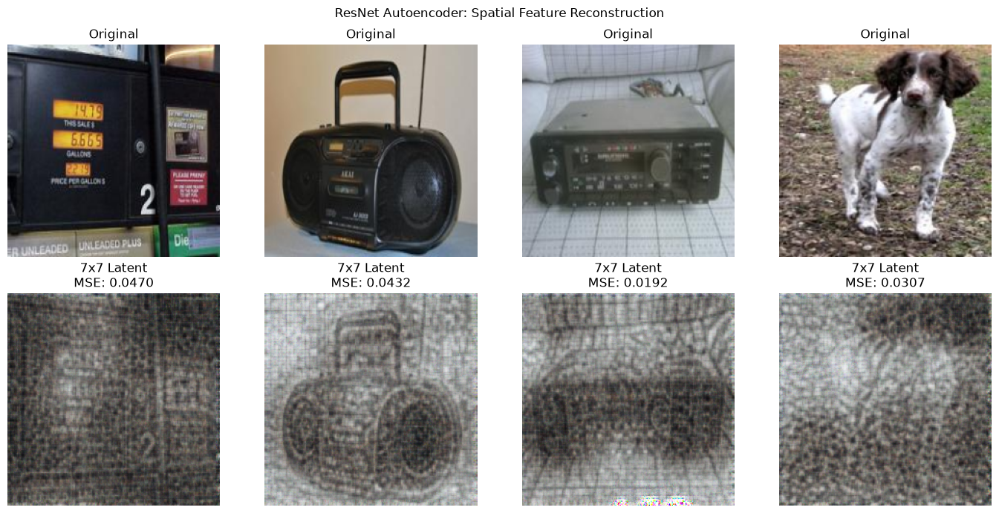

In [18]:
decoder_spatial.eval()

with torch.inference_mode():
    spatial_output = reconstruct_spatial(
        val_images.to(device)
    ).cpu()

inputs = val_images.cpu()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(4):
    axes[0, i].imshow(inputs[i].permute(1, 2, 0))
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        spatial_output[i].permute(1, 2, 0).clamp(0, 1)
    )

    mse = torch.mean(
        (inputs[i] - spatial_output[i]) ** 2
    ).item()

    axes[1, i].set_title(f"7x7 Latent\nMSE: {mse:.4f}")
    axes[1, i].axis("off")

plt.suptitle("ResNet Autoencoder: Spatial Feature Reconstruction")
plt.tight_layout()
plt.savefig("spatial_reconstructions.png", dpi=150)
plt.show()

## 12. Held-out evaluation — MSE, PSNR, and a simple baseline

The 128 images used for validation/checkpoint selection are excluded from this evaluation subset, leaving 3,797 images from the ImageNette validation directory. We compare the original 1×1 model, the spatial 7×7 model, and a constant-gray baseline.

Reported MSE is total squared pixel error divided by the total number of pixel values. With inputs in [0, 1], PSNR is calculated as:

$$\mathrm{PSNR}=10\log_{10}\!\left(\frac{1}{\mathrm{MSE}}\right).$$

Lower MSE and higher PSNR indicate better numerical pixel reconstruction. These numbers do not directly measure perceptual realism.

Evaluation caution: These images were initially withheld from checkpoint selection, but they are revisited in later experiments; they should not be described as a completely untouched final test set after that reuse.

In [19]:
import math
from torch.utils.data import Subset, DataLoader
from tqdm.auto import tqdm

# Restore the best saved models
decoder.load_state_dict(
    torch.load(
        "best_original_5epoch_control.pth",
        map_location=device,
        weights_only=True
    )
)

decoder_spatial.load_state_dict(
    torch.load(
        "best_spatial_decoder.pth",
        map_location=device,
        weights_only=True
    )
)

encoder.eval()
encoder_spatial.eval()
decoder.eval()
decoder_spatial.eval()

# Exclude the 128 validation images used for tuning
used_indices = set(int(i) for i in val_indices)

heldout_indices = [
    i for i in range(len(val_dataset))
    if i not in used_indices
]

heldout_loader = DataLoader(
    Subset(val_dataset, heldout_indices),
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Untouched evaluation images:", len(heldout_indices))

total_squared_error = {
    "Original 1x1": 0.0,
    "Spatial 7x7": 0.0,
    "Gray baseline": 0.0
}

total_pixels = 0

with torch.inference_mode():
    for x, _ in tqdm(heldout_loader, desc="Final evaluation"):
        x = x.to(device)
        normalized = (x - mean) / std

        features_1, indices_1 = encoder(normalized)
        features_7, indices_7 = encoder_spatial(normalized)

        pred_1 = decoder(features_1, indices_1)
        pred_7 = decoder_spatial(features_7, indices_7)

        total_squared_error["Original 1x1"] += (
            (pred_1 - x).square().sum().item()
        )

        total_squared_error["Spatial 7x7"] += (
            (pred_7 - x).square().sum().item()
        )

        total_squared_error["Gray baseline"] += (
            (0.5 - x).square().sum().item()
        )

        total_pixels += x.numel()

print("\nFINAL HELD-OUT RESULTS")

for name, error in total_squared_error.items():
    mse = error / total_pixels
    psnr = 10 * math.log10(1.0 / mse)

    print(f"{name}")
    print(f"  MSE:  {mse:.6f}")
    print(f"  PSNR: {psnr:.2f} dB")

Untouched evaluation images: 3797


Final evaluation: 100%|██████████| 475/475 [00:34<00:00, 13.91it/s]


FINAL HELD-OUT RESULTS
Original 1x1
  MSE:  0.067575
  PSNR: 11.70 dB
Spatial 7x7
  MSE:  0.048511
  PSNR: 13.14 dB
Gray baseline
  MSE:  0.083396
  PSNR: 10.79 dB


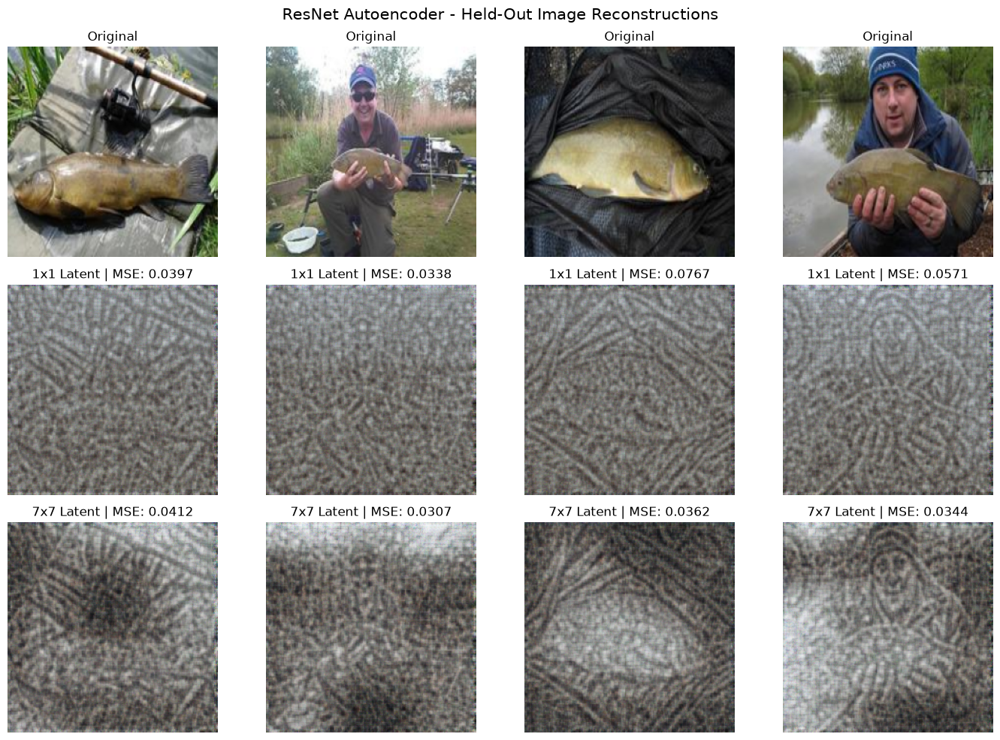

In [20]:
# Final visualization using held-out images

encoder.eval()
encoder_spatial.eval()
decoder.eval()
decoder_spatial.eval()

# Take four previously untouched evaluation images
test_images, _ = next(iter(heldout_loader))
test_images = test_images[:4].to(device)

with torch.inference_mode():
    normalized = (test_images - mean) / std

    features_1, indices_1 = encoder(normalized)
    features_7, indices_7 = encoder_spatial(normalized)

    pred_1 = decoder(features_1, indices_1)
    pred_7 = decoder_spatial(features_7, indices_7)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for i in range(4):
    original = test_images[i].cpu()
    output_1 = pred_1[i].cpu()
    output_7 = pred_7[i].cpu()

    mse_1 = ((original - output_1) ** 2).mean().item()
    mse_7 = ((original - output_7) ** 2).mean().item()

    axes[0, i].imshow(original.permute(1, 2, 0))
    axes[0, i].set_title("Original")

    axes[1, i].imshow(
        output_1.permute(1, 2, 0).clamp(0, 1)
    )
    axes[1, i].set_title(f"1x1 Latent | MSE: {mse_1:.4f}")

    axes[2, i].imshow(
        output_7.permute(1, 2, 0).clamp(0, 1)
    )
    axes[2, i].set_title(f"7x7 Latent | MSE: {mse_7:.4f}")

    for row in range(3):
        axes[row, i].axis("off")

plt.suptitle(
    "ResNet Autoencoder - Held-Out Image Reconstructions",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    "heldout_reconstruction_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

## 13. Visual comparison across different ImageNette categories

The first held-out visualization took consecutive images, which came from the same class because ImageFolder sorts paths. This step selects one image from each of four different classes for a more informative qualitative comparison.

Use the same images for every model and note both strengths and failure cases. A figure with diverse examples is easier to interpret than one with four nearly identical categories.

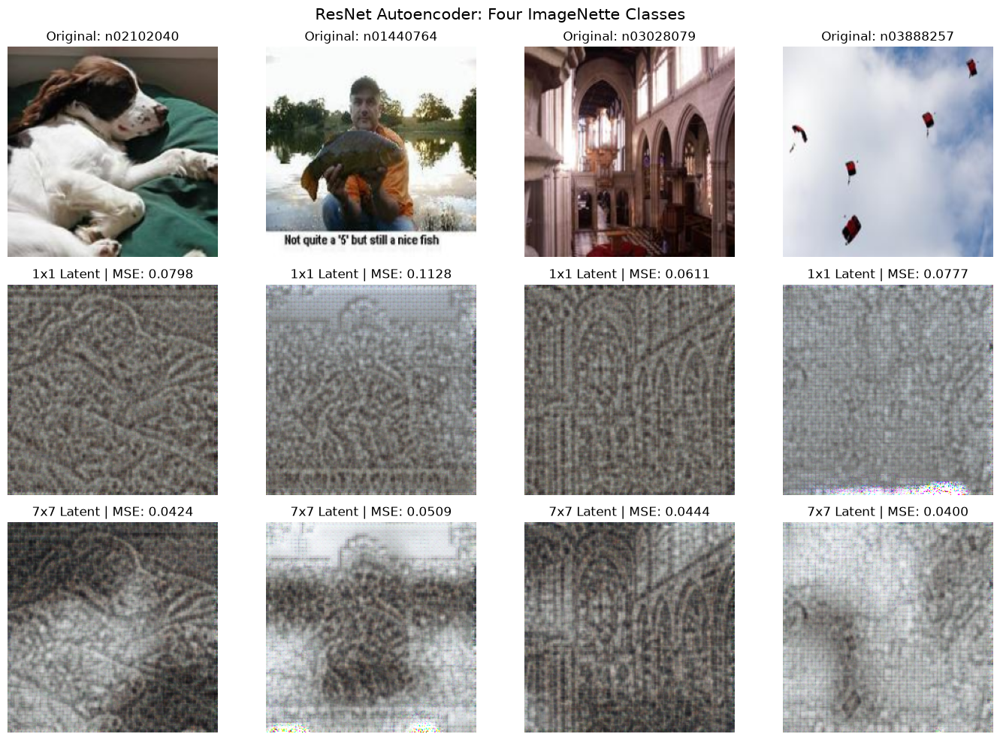

In [21]:
import random

rng = random.Random(42)

# Group unused validation images by class
by_class = {}

for idx in heldout_indices:
    label = val_dataset.targets[idx]
    by_class.setdefault(label, []).append(idx)

# Select four different classes reproducibly
selected_classes = rng.sample(
    sorted(by_class.keys()), 4
)

selected_indices = [
    rng.choice(by_class[label])
    for label in selected_classes
]

# Load selected images
samples = [val_dataset[i][0] for i in selected_indices]
test_batch = torch.stack(samples).to(device)

encoder.eval()
encoder_spatial.eval()
decoder.eval()
decoder_spatial.eval()

with torch.inference_mode():
    norm = (test_batch - mean) / std

    f1, i1 = encoder(norm)
    f7, i7 = encoder_spatial(norm)

    out1 = decoder(f1, i1).cpu()
    out7 = decoder_spatial(f7, i7).cpu()

originals = test_batch.cpu()

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for j, label in enumerate(selected_classes):
    original = originals[j]

    axes[0, j].imshow(original.permute(1, 2, 0))
    axes[0, j].set_title(
        f"Original: {val_dataset.classes[label]}"
    )

    for row, prediction, name in [
        (1, out1[j], "1x1"),
        (2, out7[j], "7x7")
    ]:
        mse = ((original - prediction) ** 2).mean().item()
        axes[row, j].imshow(
            prediction.permute(1, 2, 0).clamp(0, 1)
        )
        axes[row, j].set_title(
            f"{name} Latent | MSE: {mse:.4f}"
        )

    for row in range(3):
        axes[row, j].axis("off")

plt.suptitle(
    "ResNet Autoencoder: Four ImageNette Classes",
    fontsize=15
)
plt.tight_layout()
plt.savefig(
    "final_multiclass_reconstructions.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

## 14. Experiment 4 — Continue 7×7 training with the full ImageNette training split

This experiment starts from the trained spatial decoder and continues optimization on all 9,469 training images, using batch size 8 and three additional epochs. The best checkpoint is selected by MSE on the same 128-image validation subset.

This changes both the quantity of training examples and the total number of gradient updates. Any improvement therefore should not be attributed to dataset size alone.

In [22]:
import copy
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Preserve the existing model
decoder_full = copy.deepcopy(decoder_spatial).to(device)

# Full training dataset
full_train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# Optimizer
optimizer_full = torch.optim.Adam(
    decoder_full.parameters(),
    lr=0.0001
)

# Reconstruction function
def reconstruct_full(x):
    normalized = (x - mean) / std

    with torch.no_grad():
        features, indices = encoder_spatial(normalized)

    return decoder_full(features, indices)

# Validation function
def evaluate_full():
    decoder_full.eval()
    total_loss = 0.0

    with torch.inference_mode():
        for x, _ in small_val_loader:
            x = x.to(device)
            pred = reconstruct_full(x)

            total_loss += (
                criterion(pred, x).item() * x.size(0)
            )

    return total_loss / len(small_val_loader.dataset)

# Keep the initial checkpoint
best_full_mse = evaluate_full()

torch.save(
    decoder_full.state_dict(),
    "best_spatial_fulltrain.pth"
)

full_train_losses = []
full_val_losses = []

MAX_EPOCHS = 3

for epoch in range(MAX_EPOCHS):
    encoder_spatial.eval()
    decoder_full.train()

    running_loss = 0.0

    for x, _ in tqdm(
        full_train_loader,
        desc=f"Full dataset epoch {epoch+1}/{MAX_EPOCHS}"
    ):
        x = x.to(device, non_blocking=True)

        optimizer_full.zero_grad(set_to_none=True)

        prediction = reconstruct_full(x)
        loss = criterion(prediction, x)

        loss.backward()
        optimizer_full.step()

        running_loss += loss.item() * x.size(0)

    train_mse = running_loss / len(full_train_loader.dataset)
    val_mse = evaluate_full()

    full_train_losses.append(train_mse)
    full_val_losses.append(val_mse)

    print(
        f"Epoch {epoch+1}: "
        f"Train MSE={train_mse:.6f}, "
        f"Validation MSE={val_mse:.6f}"
    )

    if val_mse < best_full_mse:
        best_full_mse = val_mse

        torch.save(
            decoder_full.state_dict(),
            "best_spatial_fulltrain.pth"
        )

print("\nFull dataset training completed")
print("Best validation MSE:", round(best_full_mse, 6))

Full dataset epoch 1/3: 100%|██████████| 1184/1184 [01:24<00:00, 13.99it/s]


Epoch 1: Train MSE=0.044057, Validation MSE=0.037760


Full dataset epoch 2/3: 100%|██████████| 1184/1184 [00:49<00:00, 24.11it/s]


Epoch 2: Train MSE=0.037508, Validation MSE=0.036931


Full dataset epoch 3/3: 100%|██████████| 1184/1184 [00:49<00:00, 24.04it/s]


Epoch 3: Train MSE=0.033511, Validation MSE=0.033005

Full dataset training completed
Best validation MSE: 0.033005


## 15. Re-evaluate the fully trained spatial model

The saved best checkpoint from the full-data run is evaluated on the same 3,797-image comparison subset used earlier. Using the same evaluation images allows a direct numerical comparison with the previous spatial model.

The printed MSE and PSNR measure overall pixel fidelity. 
We should still inspect reconstructions before concluding that the images look better.

In [23]:
import math

# Restore the best full-training checkpoint
decoder_full.load_state_dict(
    torch.load(
        "best_spatial_fulltrain.pth",
        map_location=device,
        weights_only=True
    )
)

decoder_full.eval()
encoder_spatial.eval()

total_error = 0.0
total_pixels = 0

with torch.inference_mode():
    for x, _ in tqdm(heldout_loader, desc="Full model evaluation"):
        x = x.to(device)

        pred = reconstruct_full(x)

        total_error += (pred - x).square().sum().item()
        total_pixels += x.numel()

full_mse = total_error / total_pixels
full_psnr = 10 * math.log10(1.0 / full_mse)

print("Previous spatial MSE: 0.048511")
print("New full-data MSE:", round(full_mse, 6))
print("Previous spatial PSNR: 13.14 dB")
print("New full-data PSNR:", round(full_psnr, 2), "dB")

improvement = (0.048511 - full_mse) / 0.048511 * 100

print("MSE improvement:", round(improvement, 2), "%")

Full model evaluation: 100%|██████████| 475/475 [00:11<00:00, 39.60it/s]

Previous spatial MSE: 0.048511
New full-data MSE: 0.032065
Previous spatial PSNR: 13.14 dB
New full-data PSNR: 14.94 dB
MSE improvement: 33.9 %


## 16. Final qualitative comparison and interpretation

This figure holds the selected examples constant while comparing the original 1×1 model, the 7×7 subset-trained model, and the 7×7 full-data-trained** model.

The models have different training histories.The 7×7 latent retains more values while the decoder also receives pooling indices, and transposed convolutions may contribute to visible grid/checkerboard artifacts, although this experiment does not isolate their cause.

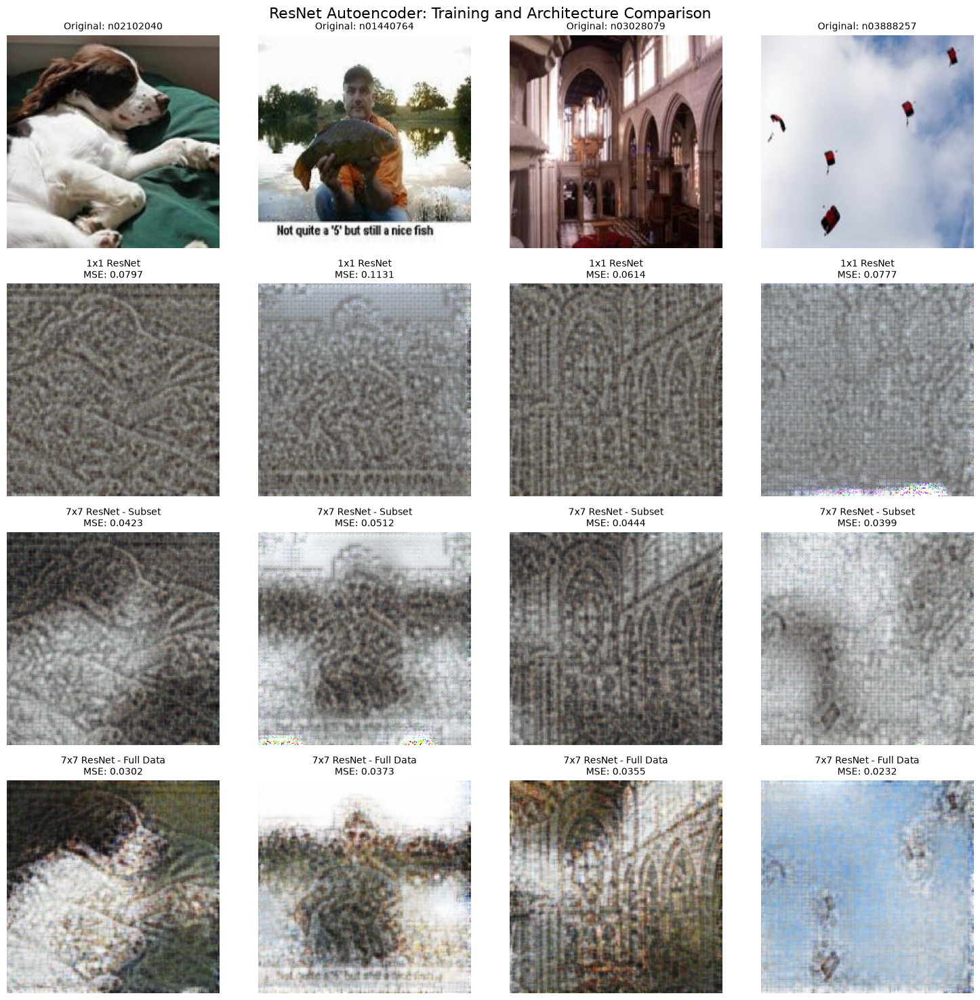

In [24]:
# Compare all trained models on the same images

decoder_full.load_state_dict(
    torch.load(
        "best_spatial_fulltrain.pth",
        map_location=device,
        weights_only=True
    )
)

for model in [
    encoder, encoder_spatial,
    decoder, decoder_spatial, decoder_full
]:
    model.eval()

# Reuse the same four ImageNette classes
x = torch.stack([
    val_dataset[i][0] for i in selected_indices
]).to(device)

with torch.inference_mode():
    normalized = (x - mean) / std

    features_1, indices_1 = encoder(normalized)
    features_7, indices_7 = encoder_spatial(normalized)

    predictions = [
        x.cpu(),
        decoder(features_1, indices_1).cpu(),
        decoder_spatial(features_7, indices_7).cpu(),
        decoder_full(features_7, indices_7).cpu()
    ]

row_names = [
    "Original",
    "1x1 ResNet",
    "7x7 ResNet - Subset",
    "7x7 ResNet - Full Data"
]

fig, axes = plt.subplots(4, 4, figsize=(15, 15))

for row in range(4):
    for col in range(4):
        img = predictions[row][col]
        axes[row, col].imshow(
            img.permute(1, 2, 0).clamp(0, 1)
        )

        if row == 0:
            label = selected_classes[col]
            title = f"Original: {val_dataset.classes[label]}"
        else:
            mse = (
                (predictions[0][col] - img) ** 2
            ).mean().item()

            title = f"{row_names[row]}\nMSE: {mse:.4f}"

        axes[row, col].set_title(title, fontsize=10)
        axes[row, col].axis("off")

plt.suptitle(
    "ResNet Autoencoder: Training and Architecture Comparison",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    "final_full_dataset_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()